In [7]:
#declaring the necesary librarys
import numpy as np
import matplotlib.pyplot as plt

Part 1 of 4: we will study the motion of a small body under the gravitational attraction of a much more massive central body. We assume that the central body remains fixed at the origin (0, 0), and that the motion takes place in the XY plane.

We will first derive the equations of motion using Newton's second law, then express them in astronomical units (AU) and finally rewrite them as a system of four first-order differential equations suitable for numerical integration using the RK4 method.

In [8]:
#defining the equations of motions with a function 
def kepler_equations(t, state):

    #extracting position and velocity components
    x, y, vx, vy = state

    #distance from the central body
    r = np.sqrt(x**2 + y**2)

    #acceleration components
    ax = -4 * np.pi**2 * x / r**3
    ay = -4 * np.pi**2 * y / r**3

    #returning the derivatives
    return np.array([vx, vy, ax, ay])

Part 2 of 4: We will study bounded elliptical orbits by numerically integrating the equations of motion using the RK4 method.

The shape of the orbit depends on the specific orbital energy, which is given by:

$$
\epsilon=\frac{1}{2}v^2-\frac{4\pi^2}{r}
$$

For a bounded orbit, the specific energy must be negative ($\epsilon<0$). We will choose suitable initial conditions, integrate the equations of motion and plot the resulting trajectory in the XY plane.

In [9]:
#defining Fourth-order Runge-Kutta method as a function
def rk4(f, X0, tlist):

    #initial time, final time and step size
    t0, tf, dt = tlist

    #creating the time array
    n = int(np.ceil((tf - t0) / dt))
    t = np.linspace(t0, tf, n + 1)

    #initialize the solution array
    X = np.zeros((n + 1, len(X0)))
    X[0] = X0

    #RK4 integration through a loop to set the values and formula
    for i in range(n):

        h = t[i + 1] - t[i]

        k1 = f(t[i], X[i])
        k2 = f(t[i] + h/2, X[i] + h*k1/2)
        k3 = f(t[i] + h/2, X[i] + h*k2/2)
        k4 = f(t[i] + h, X[i] + h*k3)

        X[i + 1] = X[i] + (h/6)*(k1 + 2*k2 + 2*k3 + k4)

    return t, X

2(a) Initial conditions

We consider an initial position of $r_0=(1,0)$ AU and an initial velocity of $v_0=(0,v_{y,0})$ AU/year, as specified in the assignment.

To obtain an elliptical orbit, we must choose an initial velocity such that the specific orbital energy is negative:

$$
\epsilon_0=\frac{1}{2}v_{y,0}^2-4\pi^2<0
$$

We choose an initial velocity of $v_{y,0}=5$ AU/year. Therefore, the initial specific energy is:

$$
\epsilon_0=\frac{1}{2}(5)^2-4\pi^2
$$

$$
\epsilon_0\approx -26.9784
$$

Since the specific energy is negative, the resulting orbit is bounded and therefore elliptical.

In [10]:
#initial position and velocity
X0 = [1.0, 0.0, 0.0, 5.0]

#obtaining the initial specific orbital energy
x0, y0, vx0, vy0 = X0

r0 = np.sqrt(x0**2 + y0**2)
v0 = np.sqrt(vx0**2 + vy0**2)

epsilon0 = 0.5 * v0**2 - (4 * np.pi**2 / r0)

#verifying the result
print("Initial specific orbital energy:", epsilon0)

Initial specific orbital energy: -26.978417604357432


In [11]:
#time interval and step size
tlist = [0, 1, 0.001]

#numerical integration using RK4 function
t, X = rk4(kepler_equations, X0, tlist)

#extract position coordinates in the 2 dimensions we're working on
x = X[:, 0]
y = X[:, 1]

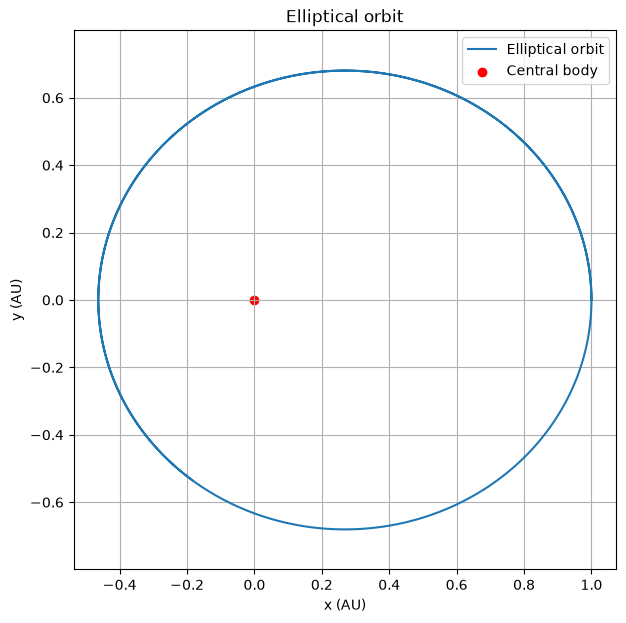

In [12]:
#plot the elliptical orbit results
plt.figure(figsize=(7, 7))

plt.plot(x, y, label='Elliptical orbit')
plt.scatter(0, 0, color='red', label='Central body')

plt.xlabel('x (AU)')
plt.ylabel('y (AU)')
plt.title('Elliptical orbit')
plt.axis('equal')
plt.grid()
plt.legend()

plt.show()

COMMENTS:  The numerical simulation produces a closed elliptical trajectory, as expected for a negative specific orbital energy. The central body is located at one of the two foci of the ellipse rather than at its geometric centre. This is consistent with Kepler's First Law. The initial energy value of approximately $-26.9784$ confirms that the orbit is bounded.

2(b) Conservation of specific orbital energy

The specific orbital energy is a conserved quantity throughout the motion. Therefore, its value should remain constant during the numerical integration.

To check the numerical stability of our simulation, we calculate the specific energy at every time step using the position and velocity obtained from the RK4 method.

The specific orbital energy is given by:

$$
\epsilon(t)=\frac{1}{2}(v_x^2+v_y^2)-\frac{4\pi^2}{r(t)}
$$

We then plot its evolution over time and compare it with the initial energy value. Any deviations from this value are caused by numerical integration errors.

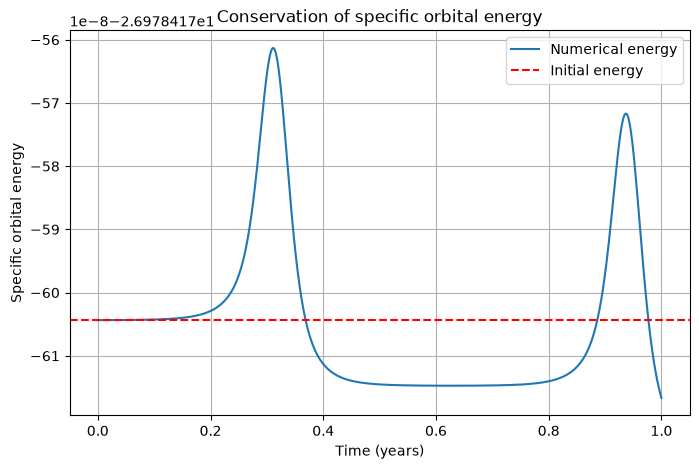

Maximum absolute energy deviation: 4.3051826992268616e-08


In [13]:
#extracting velocity components
vx = X[:, 2]
vy = X[:, 3]

#using the formula for distance from the central body
r = np.sqrt(x**2 + y**2)

#calculating the specific orbital energy at each time step
epsilon = 0.5 * (vx**2 + vy**2) - (4 * np.pi**2 / r)

#plotting the specific orbital energy over time
plt.figure(figsize=(8, 5))

plt.plot(t, epsilon, label='Numerical energy')
plt.axhline(epsilon0, color='red', linestyle='--',
            label='Initial energy')

plt.xlabel('Time (years)')
plt.ylabel('Specific orbital energy')
plt.title('Conservation of specific orbital energy')
plt.grid()
plt.legend()

plt.show()

#obtaining the maximum absolute energy deviation
max_error = np.max(np.abs(epsilon - epsilon0))

#results
print("Maximum absolute energy deviation:", max_error)

COMMENTS: The numerical energy remains very close to its initial value throughout the simulation, confirming that the specific orbital energy is well conserved. Small oscillations can be observed in the numerical energy, which are caused by the numerical errors introduced by the RK4 integration method. However, these deviations are extremely small. The maximum absolute energy deviation is approximately $4.31\times10^{-8}$, which is negligible compared to the initial energy value. Therefore, the chosen time step ($dt=0.001$) provides sufficient numerical accuracy for this simulation, and no further reduction is necessary.

2(c) Verification of Kepler's Second Law

Kepler's Second Law states that the line joining a planet and the Sun sweeps out equal areas in equal intervals of time.

Mathematically, this can be expressed as:

$$
r^2(t)\dot{\theta}(t)=\text{constant}
$$

To verify this law numerically, we first calculate the polar coordinates from the Cartesian coordinates obtained in the previous simulation:

$$
r(t)=\sqrt{x(t)^2+y(t)^2}
$$

$$
\theta(t)=\operatorname{atan2}(y(t),x(t))
$$

We use the NumPy function `np.unwrap()` to avoid discontinuities in the angular coordinate.